# 3 · Minimizzazione della likelihood
Per ciascun anello si cerca un unico spostamento temporale:
$$-\log L(\delta)=-\sum_j N_j\log\max[p_{k_j}(t_j-\delta),10^{-9}].$$
$t_j$ è il centro del bin di **FHT − ToF − t0**, con t0 fissato e indice **1,60**;
$k_j$ seleziona la PDF in base alla carica. Si usano bin di 0,25 ns e log-PDF interpolate a 0,025 ns, come nel C++.
Le PDF sono approssimate da una figura, non quelle ufficiali di JVertex.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

dati = Path("dati")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

import json
from scipy.stats import exponnorm
from scipy.optimize import minimize_scalar

esempio = json.loads((dati / "esempio.json").read_text())
parametri = np.loadtxt(dati / "pdf_parameters.txt")
classe, tempi, conteggi = np.loadtxt(dati / "istogramma_14383_anello35.csv",
                                    delimiter=",", skiprows=1, unpack=True)
raggi = np.loadtxt(dati / "r.txt")
coseni = np.loadtxt(dati / "cos_theta.txt")
mappa = np.loadtxt(dati / "delta_r.txt")
assert conteggi.sum() == esempio["hit"] and mappa.shape == (len(raggi), len(coseni))

### Minimo per un anello
Esempio: run 14383, z = 17,1 m, anello 35. Si esplora prima un intervallo largo, poi si affina il minimo. Il grafico mostra la NLL rispetto al suo minimo.

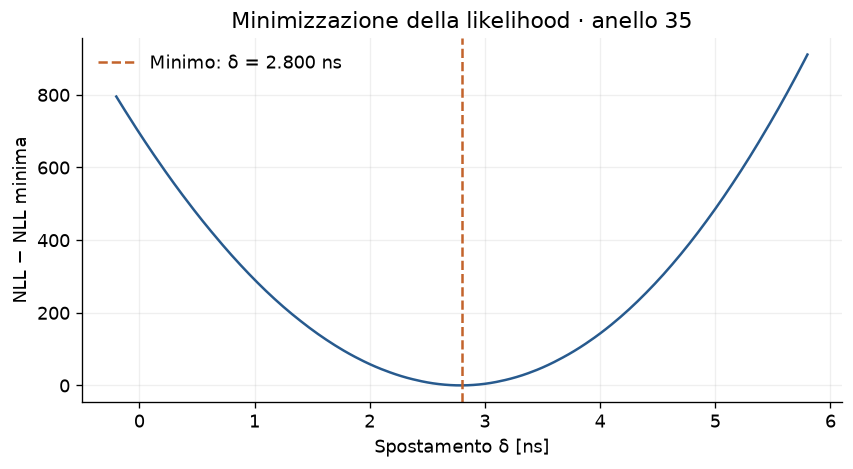

In [2]:
def pdf(t, p):
    mu, sigma, tau1, tau2, peso = p
    return (peso * exponnorm.pdf(t, tau1 / sigma, loc=mu, scale=sigma)
            + (1 - peso) * exponnorm.pdf(t, tau2 / sigma, loc=mu, scale=sigma))

griglia_pdf = -1000 + np.arange(440001) * .025
log_pdf = [np.log(np.maximum(pdf(griglia_pdf, p), 1e-9)) for p in parametri]
gruppi = [(tempi[classe == k], conteggi[classe == k]) for k in range(10)]

def nll(delta):
    return -sum(np.dot(n, np.interp(t - delta, griglia_pdf, valori,
                                   left=np.log(1e-9), right=np.log(1e-9)))
                for (t, n), valori in zip(gruppi, log_pdf))

ordine = np.argsort(tempi)
mediana = tempi[ordine][np.searchsorted(np.cumsum(conteggi[ordine]), conteggi.sum() / 2)]
scan = mediana - 290 + np.linspace(-300, 300, 121)
i = np.argmin([nll(d) for d in scan])
assert 0 < i < len(scan) - 1
fit = minimize_scalar(nll, bounds=(scan[i - 1], scan[i + 1]), method="bounded",
                      options={"xatol": 1e-6})
nodi = (np.round(fit.x / .025) + np.arange(-4, 5)) * .025
delta = min([fit.x, *nodi], key=nll)
assert abs(delta - esempio["delta_salvato_ns"]) < .026
prova = np.linspace(delta - 3, delta + 3, 241)
fig, ax = plt.subplots(figsize=(7, 3.8), layout="constrained")
ax.plot(prova, [nll(d) - nll(delta) for d in prova], color="#275a8e")
ax.axvline(delta, color="#c3632b", ls="--", label=f"Minimo: δ = {delta:.3f} ns")
ax.set(xlabel="Spostamento δ [ns]", ylabel="NLL − NLL minima",
       title="Minimizzazione della likelihood · anello 35")
ax.legend(frameon=False)
ax.grid(alpha=.2)
plt.show()

### Mappa relativa finale
Si sottrae lo spostamento del riferimento ($-0,1\leq\cos\theta<0,1$), fittato sugli hit uniti; poi si mediano i lati $\pm z$ con asse angolare invertito. Nell’esempio: $\delta_{rel}=2,800-(-4,675)=7,475$ ns.

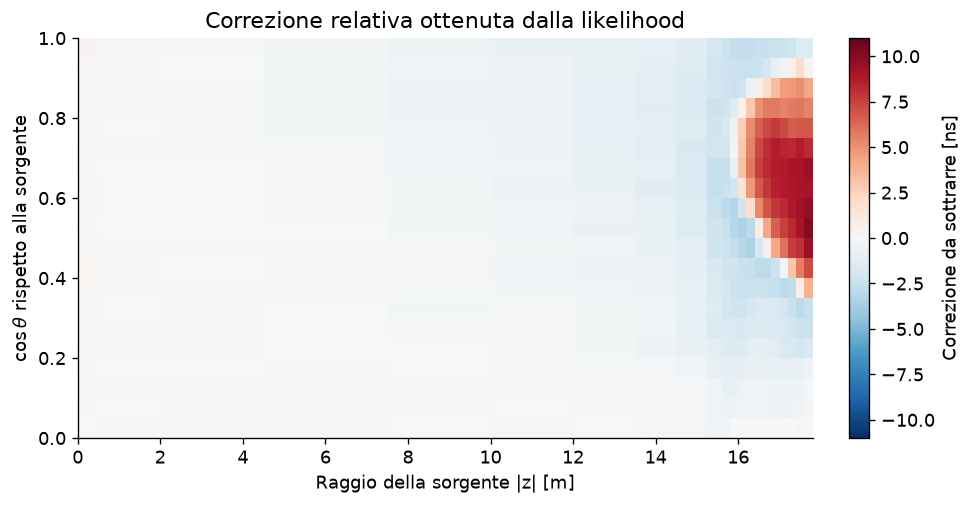

In [3]:
run_z = np.loadtxt(dati / "run_z.txt")
relative = np.loadtxt(dati / "delta_relative.txt")
per_z = dict(zip(run_z[:, 1], relative))
for r, row in zip(raggi, mappa):
    lati = ([per_z[r][20:]] if r in per_z else [])
    lati += ([per_z[-r][:20][::-1]] if -r in per_z else [])
    np.testing.assert_allclose(row, np.mean(lati, axis=0), atol=1e-10)

r_bordi = np.r_[0, (raggi[:-1] + raggi[1:]) / 2,
                raggi[-1] + (raggi[-1] - raggi[-2]) / 2] / 1000
limite = np.ceil(np.max(np.abs(mappa)))
fig, ax = plt.subplots(figsize=(8, 4.1), layout="constrained")
im = ax.pcolormesh(r_bordi, np.linspace(0, 1, 21), mappa.T,
                   cmap="RdBu_r", vmin=-limite, vmax=limite)
ax.set(xlabel="Raggio della sorgente |z| [m]", ylabel=r"$\cos\theta$ rispetto alla sorgente",
       title="Correzione relativa ottenuta dalla likelihood")
fig.colorbar(im, ax=ax, label="Correzione da sottrarre [ns]")
plt.show()

A **17,5 e 17,7 m** è disponibile soltanto il lato positivo. Qui si stima la mappa: l’effetto sul bias richiede una successiva ricostruzione e una verifica su dati indipendenti.